<a href="https://colab.research.google.com/github/YiruiLi2004/MSSP6070/blob/main/Modules/Week_8/participationactivity8_yiruili.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
## 1. Load and Prepare the Internet Sales Data
import os
import subprocess

repo_url = "https://github.com/YiruiLi2004/MSSP6070.git"
repo_path = "/content/MSSP6070"

if not os.path.exists(repo_path):
    subprocess.run(["git", "clone", repo_url], check=True)

os.chdir(repo_path)
print(os.getcwd())

/content/MSSP6070


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
sales = pd.read_csv(
    "data/InternetSales.csv",
    encoding="cp1252",
    low_memory=False
)

sales.head()

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [4]:
## 2. Create Monthly Sales and a 12-Month Rolling Trend
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"])
sales = sales.set_index("OrderDate")

In [5]:
monthly_sales = sales["SalesAmount"].resample("MS").sum()
monthly_sales.head()

,SalesAmount
OrderDate,
2010-12-01,43421.0364
2011-01-01,469823.9148
2011-02-01,466334.9030
2011-03-01,485198.6594
2011-04-01,502073.8458


In [6]:
rolling_sales = monthly_sales.rolling(12).mean()

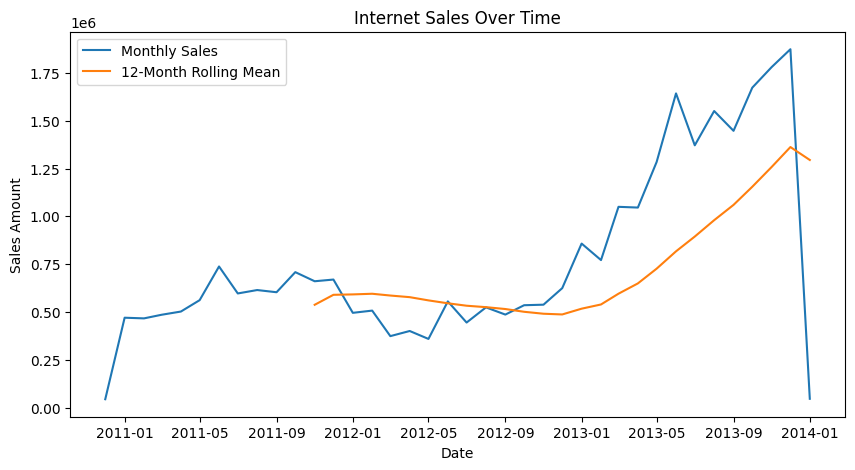

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales, label="Monthly Sales")
plt.plot(rolling_sales.index, rolling_sales, label="12-Month Rolling Mean")

plt.title("Internet Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Sales Amount")
plt.legend()

plt.show()

In [8]:
## 3. Forecast Internet Sales for the Next Five Years
trend = rolling_sales.dropna()

x = np.arange(len(trend))
y = trend.values

slope, intercept = np.polyfit(x, y, 1)

In [9]:
future_dates = pd.date_range(
    start=monthly_sales.index.max() + pd.offsets.MonthBegin(1),
    periods=60,
    freq="MS"
)

future_x = np.arange(len(trend), len(trend) + 60)
forecast_values = slope * future_x + intercept

forecast = pd.Series(
    forecast_values,
    index=future_dates,
    name="Forecast"
)

forecast.head()

,Forecast
2014-02-01,1.108985e+06
2014-03-01,1.136654e+06
2014-04-01,1.164323e+06
2014-05-01,1.191992e+06
2014-06-01,1.219662e+06


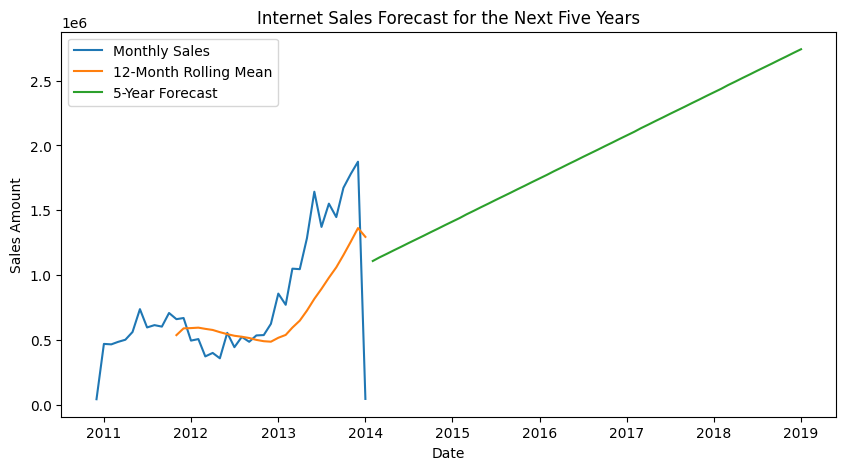

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales, label="Monthly Sales")
plt.plot(rolling_sales.index, rolling_sales, label="12-Month Rolling Mean")
plt.plot(forecast.index, forecast, label="5-Year Forecast")

plt.title("Internet Sales Forecast for the Next Five Years")
plt.xlabel("Date")
plt.ylabel("Sales Amount")
plt.legend()

plt.show()

In [11]:
forecast_yearly = forecast.resample("YS").sum()
forecast_yearly

,Forecast
2014-01-01,1.372064e+07
2015-01-01,1.878630e+07
2016-01-01,2.277065e+07
2017-01-01,2.675500e+07
2018-01-01,3.073935e+07
2019-01-01,2.741461e+06


In [12]:
## 4. Identify the Product with the Highest Sales
product_sales = (
    sales.groupby("EnglishProductName")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
)

product_sales.head(10)

,SalesAmount
EnglishProductName,
"Mountain-200 Black, 46",1.373470e+06
"Mountain-200 Black, 42",1.363142e+06
"Mountain-200 Silver, 38",1.339463e+06
"Mountain-200 Silver, 46",1.301100e+06
"Mountain-200 Black, 38",1.294866e+06
"Mountain-200 Silver, 42",1.257435e+06
"Road-150 Red, 48",1.205877e+06
"Road-150 Red, 62",1.202299e+06
"Road-150 Red, 52",1.080638e+06


In [13]:
top_product = product_sales.idxmax()
top_product_sales = product_sales.max()

print("Top product:", top_product)
print("Total sales:", top_product_sales)

Top product: Mountain-200 Black, 46
Total sales: 1373469.5481999998


Using total historical sales by product, Mountain-200 Black, 46 has the highest sales, with approximately $1.37 million.

In [14]:
product_sales.describe()

,SalesAmount
count,1.300000e+02
mean,2.258360e+05
std,3.468296e+05
min,2.427300e+03
25%,2.541092e+04
50%,5.543849e+04
75%,3.077246e+05
max,1.373470e+06
